# Тюнинг линейной регрессии и анализ ошибок

В работе сравниваются Ridge ($L_2$) и Lasso ($L_1$), подбирается коэффициент регуляризации по кросс-валидации и проверяется влияние удаления выбросов.

Все решения воспроизводимы: фиксирован `random_state=241`, а тестовая выборка используется только для финальной оценки.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_predict, cross_val_score, train_test_split

warnings.filterwarnings("ignore", category=UserWarning)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)
RANDOM_STATE = 241

## Данные и разбиение

В датасете diabetes 442 объекта и 10 уже стандартизованных признаков. Разделение 70/30 позволяет обучать и настраивать модели на одной части данных, а качество оценивать на ранее не виденной части.

In [2]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, train_size=0.7, random_state=RANDOM_STATE
)

print(f"Обучающая выборка: {X_train.shape}")
print(f"Тестовая выборка:   {X_test.shape}")
print("Признаки:", ", ".join(data.feature_names))

Обучающая выборка: (309, 10)
Тестовая выборка:   (133, 10)
Признаки: age, sex, bmi, bp, s1, s2, s3, s4, s5, s6


## Задание 1. Ridge и Lasso

Ridge добавляет к функции потерь штраф $\alpha\sum_j w_j^2$ и плавно уменьшает коэффициенты. Lasso использует штраф $\alpha\sum_j |w_j|$ и умеет занулять коэффициенты, то есть одновременно выполнять отбор признаков.

Коэффициент считаем практически нулевым при $|w| < 1$. Для данного масштаба целевой переменной и стандартизованных признаков это консервативный и наглядный порог; дополнительно ниже показаны сами значения коэффициентов.

In [3]:
zero_tol = 1.0
default_models = {
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=100_000),
}

default_coefs = {}
for name, model in default_models.items():
    model.fit(X_train, y_train)
    default_coefs[name] = model.coef_

coef_table = pd.DataFrame(default_coefs, index=data.feature_names)
coef_table.loc["Практически нулевых"] = (coef_table.abs() < zero_tol).sum()
coef_table

,Ridge,Lasso
age,20.8659,0.0000
sex,-58.0004,0.0000
bmi,231.2705,274.3313
bp,186.6701,48.5720
s1,33.3109,0.0000
s2,-2.1699,0.0000
s3,-150.9505,-0.0000
s4,141.3504,0.0000
s5,250.7539,424.1214
s6,123.1803,0.0000


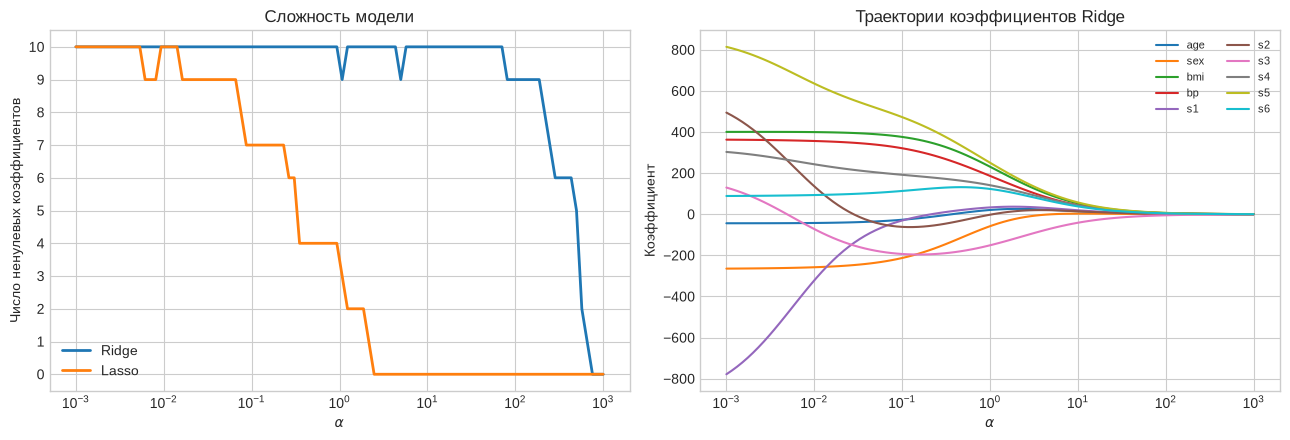

In [4]:
alphas = np.logspace(-3, 3, 100)
ridge_coefs, lasso_coefs = [], []

for alpha in alphas:
    ridge_coefs.append(Ridge(alpha=alpha).fit(X_train, y_train).coef_)
    lasso_coefs.append(
        Lasso(alpha=alpha, max_iter=100_000).fit(X_train, y_train).coef_
    )

ridge_coefs = np.asarray(ridge_coefs)
lasso_coefs = np.asarray(lasso_coefs)
ridge_nonzero = (np.abs(ridge_coefs) >= zero_tol).sum(axis=1)
lasso_nonzero = (np.abs(lasso_coefs) >= zero_tol).sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].semilogx(alphas, ridge_nonzero, label="Ridge", linewidth=2)
axes[0].semilogx(alphas, lasso_nonzero, label="Lasso", linewidth=2)
axes[0].set(xlabel=r"$\alpha$", ylabel="Число ненулевых коэффициентов",
            title="Сложность модели")
axes[0].set_yticks(range(11))
axes[0].legend()

for i, feature in enumerate(data.feature_names):
    axes[1].semilogx(alphas, ridge_coefs[:, i], label=feature)
axes[1].set(xlabel=r"$\alpha$", ylabel="Коэффициент",
            title="Траектории коэффициентов Ridge")
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

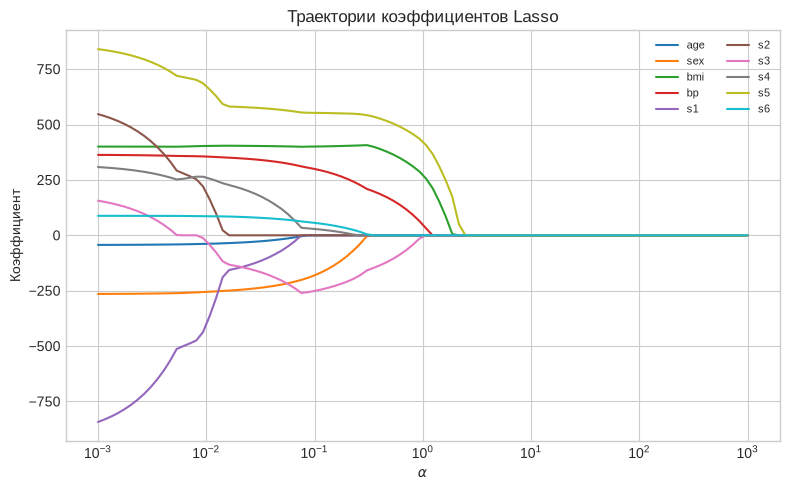

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, feature in enumerate(data.feature_names):
    ax.semilogx(alphas, lasso_coefs[:, i], label=feature)
ax.set(xlabel=r"$\alpha$", ylabel="Коэффициент",
       title="Траектории коэффициентов Lasso")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

**Вывод.** С ростом $\alpha$ обе модели сильнее сжимают коэффициенты. Ridge делает это плавно, а Lasso последовательно обращает часть коэффициентов точно в ноль. Поэтому Lasso даёт разреженную модель, а Ridge обычно сохраняет все признаки. Под «итерацией» в формулировке задания разумно понимать шаг по сетке $\alpha$: у линейной Ridge-регрессии нет содержательной последовательности коэффициентов по итерациям оптимизатора, зато путь регуляризации показывает требуемый эффект.

### Метрики Ridge с параметрами по умолчанию

- $RMSE = \sqrt{\frac{1}{n}\sum (y_i-\hat y_i)^2}$ — сильнее штрафует крупные ошибки; меньше — лучше.
- $MAE = \frac{1}{n}\sum |y_i-\hat y_i|$ — устойчивее к выбросам; меньше — лучше.
- $R^2 = 1 - \frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ — доля объяснённой дисперсии; больше — лучше.

In [6]:
def regression_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

ridge_default = Ridge().fit(X_train, y_train)
default_metrics = regression_metrics(y_test, ridge_default.predict(X_test))
pd.DataFrame([default_metrics], index=["Ridge, alpha=1"] )

,RMSE,MAE,R2
"Ridge, alpha=1",58.3043,49.6028,0.3599


### Подбор $\alpha$ по кросс-валидации

Для каждой метрики перебирается одна и та же логарифмическая сетка от $10^{-3}$ до $10^3$. Используется 5-fold кросс-валидация только на обучающей выборке. Это не даёт информации из теста попасть в настройку модели.

In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scorings = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2",
}
cv_results = {}
best_alphas = {}

for metric, scoring in scorings.items():
    scores = np.array([
        cross_val_score(Ridge(alpha=alpha), X_train, y_train,
                        cv=cv, scoring=scoring).mean()
        for alpha in alphas
    ])
    values = -scores if metric in {"RMSE", "MAE"} else scores
    cv_results[metric] = values
    best_index = np.argmin(values) if metric in {"RMSE", "MAE"} else np.argmax(values)
    best_alphas[metric] = alphas[best_index]

pd.Series(best_alphas, name="Лучший alpha").to_frame()

,Лучший alpha
RMSE,0.0010
MAE,0.0011
R2,0.0572


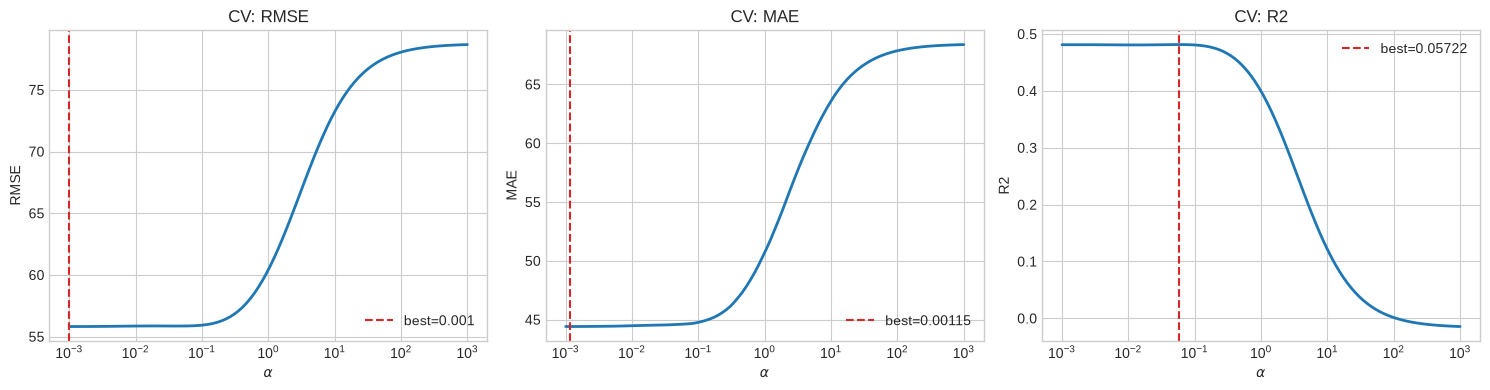

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, scorings):
    ax.semilogx(alphas, cv_results[metric], linewidth=2)
    ax.axvline(best_alphas[metric], color="tab:red", linestyle="--",
               label=f"best={best_alphas[metric]:.4g}")
    ax.set(xlabel=r"$\alpha$", ylabel=metric, title=f"CV: {metric}")
    ax.legend()
plt.tight_layout()
plt.show()

In [9]:
test_rows = [{"Модель": "Ridge, alpha=1", "alpha": 1.0, **default_metrics}]
for optimized_metric, alpha in best_alphas.items():
    model = Ridge(alpha=alpha).fit(X_train, y_train)
    test_rows.append({
        "Модель": f"Ridge, подбор по {optimized_metric}",
        "alpha": alpha,
        **regression_metrics(y_test, model.predict(X_test)),
    })

test_results = pd.DataFrame(test_rows).set_index("Модель")
test_results

,alpha,RMSE,MAE,R2
Модель,,,,
"Ridge, alpha=1",1.0000,58.3043,49.6028,0.3599
"Ridge, подбор по RMSE",0.0010,55.8576,47.1554,0.4125
"Ridge, подбор по MAE",0.0011,55.8509,47.1501,0.4126
"Ridge, подбор по R2",0.0572,55.6536,47.1725,0.4168


**Вывод.** Настройка заметно улучшает качество относительно `alpha=1`: RMSE и MAE уменьшаются, а $R^2$ растёт. Оптимальные значения для разных критериев могут отличаться, потому что метрики по-разному оценивают ошибки. Лучший по CV параметр не обязан дать лучший результат по той же метрике на одном конкретном тестовом разбиении — CV оценивает среднее качество на нескольких разбиениях.

## Задание 2. Поиск объектов-выбросов

Ошибки на обучающих объектах получаем через `cross_val_predict`: прогноз для каждого объекта сделан моделью, которая этот объект не видела. Обычные остатки обученной на всех данных модели были бы слишком оптимистичными.

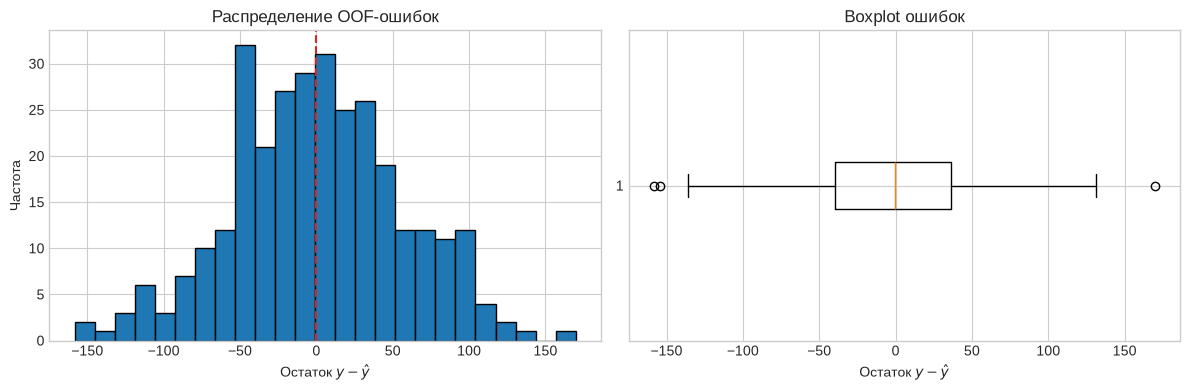

,Остатки
count,309.0000
mean,0.4998
std,55.9787
min,-158.4216
25%,-39.9915
50%,-0.2715
75%,36.0797
max,169.8043


In [10]:
alpha_rmse = best_alphas["RMSE"]
oof_predictions = cross_val_predict(
    Ridge(alpha=alpha_rmse), X_train, y_train, cv=cv
)
residuals = y_train - oof_predictions

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(residuals, bins=25, edgecolor="black")
axes[0].axvline(0, color="tab:red", linestyle="--")
axes[0].set(xlabel=r"Остаток $y-\hat y$", ylabel="Частота",
            title="Распределение OOF-ошибок")
axes[1].boxplot(residuals, orientation="horizontal")
axes[1].set(xlabel=r"Остаток $y-\hat y$", title="Boxplot ошибок")
plt.tight_layout()
plt.show()

pd.Series(residuals).describe().to_frame("Остатки")

Распределение сосредоточено около нуля, но имеет длинные хвосты: есть несколько объектов с очень крупными положительными и отрицательными ошибками. Из-за возведения ошибки в квадрат такие наблюдения заметно влияют на MSE/RMSE.

In [11]:
q1, q3 = np.quantile(residuals, [0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
inlier_mask = (residuals >= lower_bound) & (residuals <= upper_bound)

print(f"Границы IQR: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Удалено объектов: {(~inlier_mask).sum()} из {len(y_train)}")

ridge_before = Ridge(alpha=alpha_rmse).fit(X_train, y_train)
ridge_after = Ridge(alpha=alpha_rmse).fit(X_train[inlier_mask], y_train[inlier_mask])

outlier_comparison = pd.DataFrame(
    [
        regression_metrics(y_test, ridge_before.predict(X_test)),
        regression_metrics(y_test, ridge_after.predict(X_test)),
    ],
    index=["До удаления", "После удаления"],
)
outlier_comparison

Границы IQR: [-154.10, 150.19]
Удалено объектов: 3 из 309


,RMSE,MAE,R2
До удаления,55.8576,47.1554,0.4125
После удаления,56.0121,47.0615,0.4092


**Вывод.** По правилу $1.5\,IQR$ удаляются только несколько наиболее крайних обучающих объектов. На тесте MAE слегка улучшается, но RMSE и $R^2$ немного ухудшаются. Значит, крупная ошибка ещё не доказывает, что объект ошибочный: он может быть редким, но закономерным наблюдением. Кроме того, в тесте тоже остаются сложные объекты. Поэтому автоматическое удаление выбросов не гарантирует улучшения; для production-задачи сначала нужно исследовать причины аномалий или использовать робастную функцию потерь.

## Задание 3. Итоговый отчёт

1. Данные разделены на обучение и тест 70/30; тест не участвовал в настройке.
2. Ridge и Lasso обучены с параметрами по умолчанию. Lasso занулил большую часть коэффициентов, Ridge лишь сжал их.
3. По сетке $10^{-3}\ldots10^3$ построены пути коэффициентов и зависимость числа ненулевых весов от регуляризации.
4. Для Ridge рассчитаны RMSE, MAE и $R^2$. Параметр $\alpha$ отдельно подобран по каждой метрике с 5-fold CV. Настройка улучшила качество по сравнению с `alpha=1`.
5. Выбросы найдены по честным out-of-fold остаткам и правилу $1.5\,IQR$. Их удаление не улучшило модель по всем критериям, поэтому считать его безусловно полезным нельзя.

Главная идея: регуляризация управляет компромиссом между сложностью и устойчивостью модели, а любое решение о гиперпараметрах или выбросах нужно проверять на данных, не использованных для обучения.